# Лабораторная работа 3 - Метод наименьших квадратов. Линейная регрессия

Сгенерировать данные, используя заданное распределение и связанное уравнение.

Вариант 2:

- $N = 10\,000$ - количество точек
- $X$ - равномерное распределение от 1 до 50
- $E$ - нормальное распределение с центром 1 и отклонением 10
- $Y = -3 + 0.5X + E$

In [3]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

rng = np.random.default_rng()

N = 10_000
X = rng.uniform(1, 50, N)
E = rng.normal(1, 10, N)
Y = -3 + 0.5 * X + E

df = pd.DataFrame({
    "X": X,
    "E": E,
    "Y": Y
})
df

,X,E,Y
0,49.721766,13.977368,35.838251
1,15.219299,3.323376,7.933026
2,23.039283,10.395140,18.914782
3,31.778727,-3.943904,8.945460
4,36.863968,11.490652,26.922637
...,...,...,...
9995,31.635633,3.184927,16.002743
9996,38.131622,0.364798,16.430609
9997,34.775155,-12.028212,2.359365
9998,35.553370,-3.915446,10.861238


Найти уравнение прямой линейной регрессии методом наименьших квадратов

$$\hat{y} = \beta_0 + \beta_1 x$$

Ищем такие $\beta_0, \beta_1$, при которых сумма квадратов остатков минимальна:

$$S(\beta_0, \beta_1) = \sum_{i=1}^{N} (y_i - \beta_0 - \beta_1 x_i)^2 \to \min$$

Приравниваем частные производные к нулю и получаем:

$$\beta_1 = \frac{N \sum x_i y_i - \sum x_i \sum y_i}{N \sum x_i^2 - (\sum x_i)^2}, \qquad \beta_0 = \bar{y} - \beta_1 \bar{x}$$

In [4]:
def mean(x):
    return np.sum(x) / len(x)

def mnk(x, y):
    n = len(x)
    #                                                       (x.T @ x - так быстрее)
    b1 = (n * np.sum(x * y) - np.sum(x) * np.sum(y)) / (n * np.sum(x ** 2) - (np.sum(x)) ** 2)
    b0 = mean(y) - b1 * mean(x)
    return b0, b1

Получить коэффициенты для линейной регрессии

In [12]:
b0, b1 = mnk(X, Y)

print(f"b0: {b0:.4f}, b1: {b1:.4f}")
polyfit = np.polyfit(X, Y, 1)
print(f"b0: {polyfit[1]:.4f}, b1: {polyfit[0]:.4f}")
print(np.isclose(b0, polyfit[1]), np.isclose(b1, polyfit[0]))

b0: -1.9710, b1: 0.4905
b0: -1.9710, b1: 0.4905
True True


Построить прямую согласно найденным коэффициентам и отобразить точки датасета

Построить прямую согласно выражению $Y$

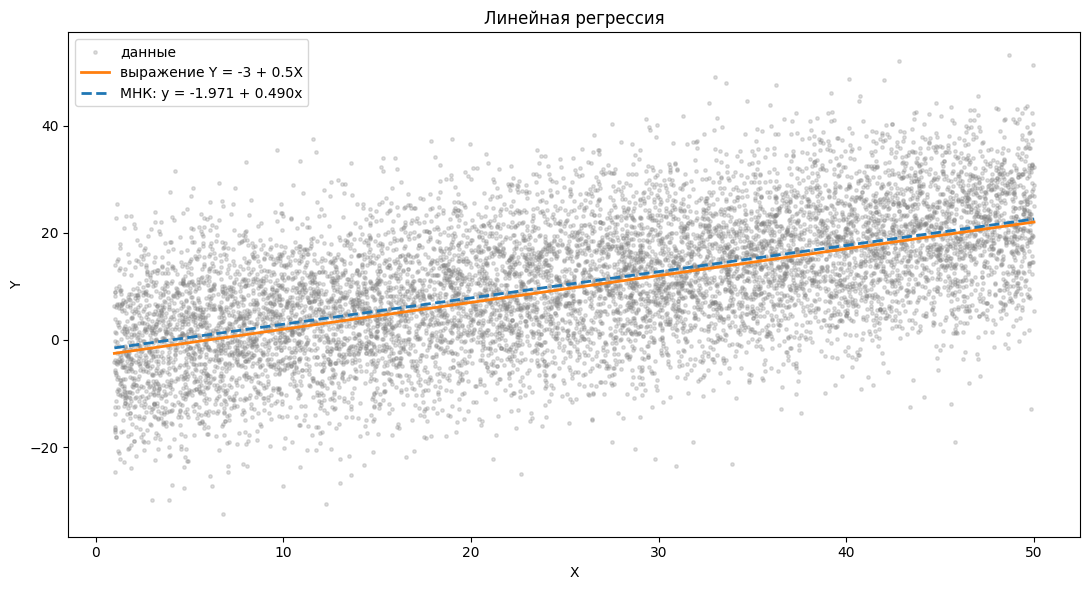

In [16]:
line_x = np.array([1, 50])

plt.figure(figsize=(11, 6))
# scatter -- строим ТОЧКИ на графике
# plot -- рисует график функции
plt.scatter(X, Y, s=6, alpha=0.25, color="gray", label="данные")
plt.plot(line_x, -3 + 0.5 * line_x, color="tab:orange", linewidth=2, label="выражение Y = -3 + 0.5X")
plt.plot(line_x, b0 + b1 * line_x, color="tab:blue", linestyle="--", linewidth=2, label=f"МНК: y = {b0:.3f} + {b1:.3f}x")
plt.title("Линейная регрессия")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.tight_layout()
plt.show()

Найти метрики оценки качества

$$MSE = \frac{1}{N} \sum (y_i - \hat{y}_i)^2$$

$$R^2 = 1 - \frac{\sum (y_i - \hat{y}_i)^2}{\sum (y_i - \bar{y})^2}$$

$$MAPE = \frac{100\%}{N} \sum \left| \frac{y_i - \hat{y}_i}{y_i} \right|$$

In [24]:
def metrics(y, y_pred):
    mse = mean((y - y_pred) ** 2)
    r2 = 1 - (np.sum( (y - y_pred) ** 2) ) / (np.sum( (y - mean(y)) ** 2) )
    mape = mean(np.abs( (y - y_pred) / y) ) * 100
    return mse, r2, mape

Y_pred = b0 + b1 * X
mse, r2, mape = metrics(Y, Y_pred)

print(f'MSE: {mse:.4f}')
print(f'r2: {r2:.4f}')
print(f'MAPE: {mape:.1f}%')

MSE: 100.0240
r2: 0.3237
MAPE: 447.3%


Сравнить истинное и найденное решение

Среднее шума равно 1, а не 0, поэтому единица уходит в свободный член:

$$Y = -3 + 0.5X + E = (-3 + 1) + 0.5X + (E - 1) = -2 + 0.5X + (E - 1)$$

In [22]:
lines = {
    "выражение Y": (-3, 0.5),
    "с учётом среднего шума": (-2, 0.5),
    "МНК": (b0, b1),
}

rows = []
for name, (c0, c1) in lines.items():
    rows.append([name, c0, c1, *metrics(Y, c0 + c1 * X)])

pd.DataFrame(rows, columns=["прямая", "b0", "b1", "MSE", "R^2", "MAPE, %"]).set_index("прямая")

,b0,b1,MSE,R^2,"MAPE, %"
прямая,,,,,
выражение Y,-3.000000,0.500000,100.661006,0.319415,411.024799
с учётом среднего шума,-2.000000,0.500000,100.087578,0.323292,455.733198
МНК,-1.970989,0.490479,100.024044,0.323721,447.338513


Оценка качества по остаткам: остаток - это то, что модель не объяснила. Если прямая подходит, в остатках нет никакой закономерности

Почему MAPE такой большой: в формуле мы делим на $y_i$, а часть значений $Y$ близка к нулю

Вопрос 5. Нелинейная зависимость: прямая на параболе и на экспоненте, потом те же данные после преобразования

Вопрос 6. Размер выборки: для каждого $N$ 1000 раз генерируем новые данные и смотрим, как разбегаются коэффициенты

Вопрос 7. Выбросы: добавим три точки с $Y = -100$ на правом краю и посмотрим, как сдвинется прямая

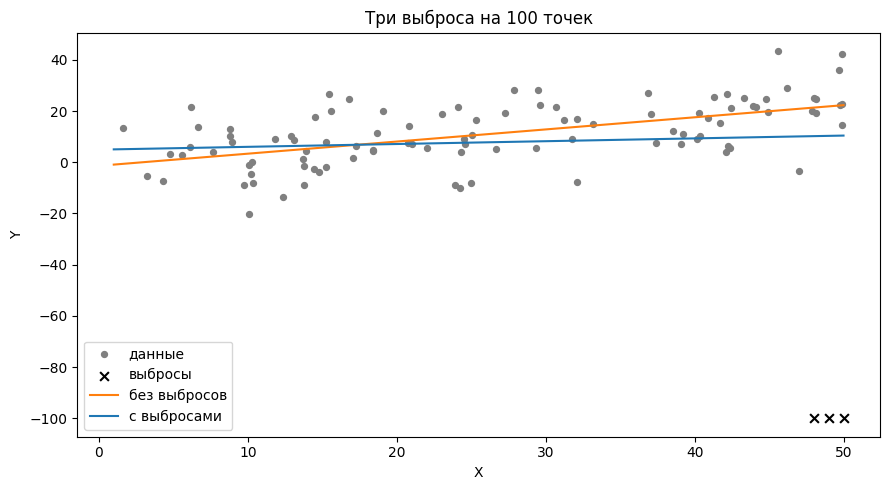

,b0,b1,MSE,R^2
выборка,,,,
100 точек,-1.399365,0.473520,100.651200,0.313653
100 точек + 3 выброса,4.912373,0.109869,489.013672,0.005244
10 000 точек,-1.970989,0.490479,100.024044,0.323721
10 000 точек + 3 выброса,-1.897404,0.486150,104.457456,0.310607


In [23]:
out_x = np.array([48, 49, 50])
out_y = np.array([-100, -100, -100])

x100, y100 = X[:100], Y[:100]
x_bad = np.concatenate([x100, out_x])
y_bad = np.concatenate([y100, out_y])
X_bad = np.concatenate([X, out_x])
Y_bad = np.concatenate([Y, out_y])

rows = []
for name, xs, ys in [
    ("100 точек", x100, y100),
    ("100 точек + 3 выброса", x_bad, y_bad),
    ("10 000 точек", X, Y),
    ("10 000 точек + 3 выброса", X_bad, Y_bad),
]:
    c0, c1 = mnk(xs, ys)
    mse_n, r2_n, _ = metrics(ys, c0 + c1 * xs)
    rows.append([name, c0, c1, mse_n, r2_n])

clean = mnk(x100, y100)
dirty = mnk(x_bad, y_bad)

plt.figure(figsize=(9, 5))
plt.scatter(x100, y100, s=18, color="gray", label="данные")
plt.scatter(out_x, out_y, s=40, color="black", marker="x", label="выбросы")
plt.plot(line_x, clean[0] + clean[1] * line_x, color="tab:orange", label="без выбросов")
plt.plot(line_x, dirty[0] + dirty[1] * line_x, color="tab:blue", label="с выбросами")
plt.title("Три выброса на 100 точек")
plt.xlabel("X")
plt.ylabel("Y")
plt.legend()
plt.tight_layout()
plt.show()

pd.DataFrame(rows, columns=["выборка", "b0", "b1", "MSE", "R^2"]).set_index("выборка")